# PAWS Project 2 — experiments and analysis

Pair classification with pretrained embeddings (`stack_diff_prod`).
Logic lives in `part2/project/*.py`. This notebook is mainly for **analysis**.

Training is off by default — flip the toggles below when you are on the GPU machine.

## Setup and toggles

In [1]:
# Flip these when you intentionally want heavy work.
RUN_TRAINING = False          # full enabled RUNS from config (GPU)
RUN_CV_PLOTS = True           # box plot of CV fold accuracies
RUN_ROPE = True               # Bayesian correlated t-test with ROPE on CV accuracies
RUN_DEVTEST_PREDS = True      # load models and score devtest (needs trained checkpoints)
RUN_BIN_PLOTS = True
RUN_GOTCHA = True
RUN_LENGTH_X_MODEL = True
RUN_BDA = True                # MCMC — can be slow

# Systems in the CV box plot and ROPE table (None = all trained runs)
CV_SYSTEMS = None

# Systems compared in devtest analysis
ANALYSIS_SYSTEMS = [
    "pool_ft300",
    "lstm_ft300",
    "bilstm_ft300",
]

# Embedding whose tokenizer is used for the avg_len_tokens feature
ANALYSIS_EMB_KEY = "fasttext300"

In [2]:
import sys
from pathlib import Path

# Notebook lives in part2/project/; repo root is two levels up.
root = Path.cwd().resolve().parent.parent
sys.path.insert(0, str(root))
print("repo root:", root)

import json

import arviz as az
import numpy as np
import pandas as pd
import torch

import part2.analysis
from part1 import baseline
from part1.baseline import data as paws_data
from part2.project import analysis, config, embeddings, experiment

print("device:", config.DEVICE)
print("results:", config.RESULTS_DIR)
print("enabled runs:", [r["id"] for r in config.enabled_runs()])

repo root: /home/joeyjdl/Documents/GitHub/nlp1-student
device: cuda
results: /home/joeyjdl/Documents/GitHub/nlp1-student/part2/project/results
enabled runs: ['pool_ft300', 'lstm_ft300', 'lstm_glove300', 'bilstm_ft300', 'bilstm_glove300']


## Data, embeddings, tokenizer

In [3]:
outcome_space, cv_splits, devtest_splits = experiment.load_paws_cv_and_devtest()
print("outcome space:", outcome_space)
print("CV seeds:", config.SEEDS, "folds:", config.NUM_FOLDS)
print("devtest size (seed 0):", len(devtest_splits[0]["devtest"]))

emb_model, tokenizer = embeddings.load_embedding_and_tokenizer(ANALYSIS_EMB_KEY)
print("embedding:", ANALYSIS_EMB_KEY, emb_model.vectors.shape)

outcome space: 0: not paraphrase, 1: paraphrase
CV seeds: [0, 3, 5] folds: 5
devtest size (seed 0): 200
embedding: fasttext300 (830463, 300)


## Training (optional)

Default is skip. On the Linux GPU machine set `RUN_TRAINING = True`, or run from the shell:

```bash
python -m part2.project.experiment
python -m part2.project.experiment --run-id pool_ft300
```

In [4]:
if RUN_TRAINING:
    summaries, _ = experiment.run_enabled(device=config.DEVICE)
    display(pd.DataFrame(summaries))
else:
    print("Skipping training (RUN_TRAINING=False).")
    summary_paths = list(config.RESULTS_DIR.glob("*/summary.json"))
    if summary_paths:
        rows = [json.loads(p.read_text(encoding="utf-8")) for p in sorted(summary_paths)]
        display(pd.DataFrame(rows))
    else:
        print("No summary.json files found yet under", config.RESULTS_DIR)

Skipping training (RUN_TRAINING=False).


,n,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,f1_per_class_mean,f1_per_class_std,run_id,enc,emb
0,15,0.846733,0.008265,0.843633,0.008814,"[0.86552, 0.821745]","[0.006596, 0.011586]",bilstm_ft300,bilstm,fasttext300
1,15,0.810706,0.006619,0.806482,0.006634,"[0.834874, 0.77809]","[0.006719, 0.008263]",bilstm_ft_subword,bilstm,fasttext300_subword
2,15,0.844497,0.006522,0.841803,0.006728,"[0.862105, 0.8215]","[0.006459, 0.009117]",bilstm_glove300,bilstm,glove300
3,15,0.813668,0.008246,0.810294,0.008698,"[0.835218, 0.78537]","[0.00742, 0.012075]",bilstm_glove50,bilstm,glove50
4,15,0.859033,0.003836,0.856300,0.004057,"[0.876005, 0.836595]","[0.003516, 0.00566]",gru_ft300,gru,fasttext300
5,15,0.847413,0.006115,0.844533,0.006478,"[0.865395, 0.823671]","[0.005658, 0.009184]",gru_glove300,gru,glove300
6,15,0.844312,0.007469,0.841102,0.008195,"[0.863462, 0.818741]","[0.005719, 0.011653]",lstm_ft300,lstm,fasttext300
7,15,0.798627,0.011635,0.794377,0.011351,"[0.82369, 0.765065]","[0.011996, 0.011827]",lstm_ft_subword,lstm,fasttext300_subword
8,15,0.840700,0.007844,0.837838,0.007902,"[0.859177, 0.816499]","[0.007736, 0.009225]",lstm_glove300,lstm,glove300
9,15,0.810811,0.007741,0.806778,0.007881,"[0.834547, 0.779009]","[0.007306, 0.009543]",lstm_glove50,lstm,glove50


## Cross-validation accuracy

Fold accuracies for every seed (run) and fold, one box per system.

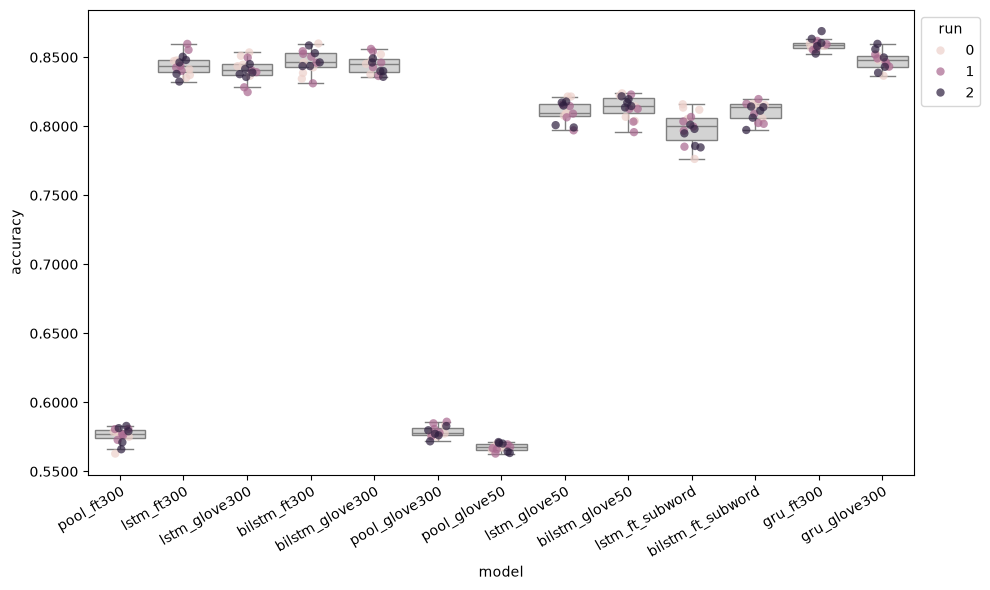

In [5]:
cv_systems = CV_SYSTEMS if CV_SYSTEMS is not None else analysis.trained_run_ids()
my_classifiers = analysis.load_cv_results(cv_systems)

if RUN_CV_PLOTS:
    baseline.analysis.plot_box_and_points(baseline.analysis.make_data_frame(my_classifiers), figsize=(10, 6))
else:
    print("Skipping CV plots.")

In [6]:
baseline.analysis.make_data_frame(my_classifiers).groupby('model', sort=False)['accuracy'].agg(['mean', 'std'])

,mean,std
model,,
pool_ft300,0.576024,0.005683
lstm_ft300,0.844312,0.007469
lstm_glove300,0.840700,0.007844
bilstm_ft300,0.846733,0.008265
bilstm_glove300,0.844497,0.006522
pool_glove300,0.578875,0.003928
pool_glove50,0.567394,0.002634
lstm_glove50,0.810811,0.007741
bilstm_glove50,0.813668,0.008246


## ROPE: Bayesian correlated t-test

Posterior over the mean CV accuracy difference B − A (Benavoli et al.), accounting for the
correlation between folds of the same run. Differences within ±`config.ROPE_SIZE` count as a tie.

Main comparisons (`config.ROPE_COMPARISONS`): BiLSTM vs LSTM, GRU vs LSTM, fastText vs GloVe (LSTM),
embed-and-pool vs LSTM, GloVe 50d vs 300d (LSTM), fastText vs fastText subword (LSTM).

In [7]:
if RUN_ROPE:
    with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
        display(analysis.compare_pairs(my_classifiers, config.ROPE_COMPARISONS, config.ROPE_SIZE))
else:
    print("Skipping ROPE table.")

,A,B,P(A wins),P(tie),P(B wins),mean diff (B-A),effect size
0,bilstm_ft300,lstm_ft300,3.233035e-01,5.772539e-01,0.099443,-0.002422,-0.440016
1,gru_ft300,lstm_ft300,9.818593e-01,1.796913e-02,0.000172,-0.014721,-3.506179
2,lstm_ft300,lstm_glove300,4.060705e-01,5.163666e-01,0.077563,-0.003612,-0.630269
3,pool_ft300,lstm_ft300,2.154198e-17,1.465501e-17,1.000000,0.268288,48.345879
4,lstm_glove50,lstm_glove300,3.628456e-07,1.525002e-05,0.999984,0.029889,7.234336
5,lstm_ft300,lstm_ft_subword,9.999887e-01,1.031591e-05,0.000001,-0.045684,-6.976539


All pairs of trained systems:

In [8]:
if RUN_ROPE:
    with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
        display(baseline.analysis.compare_all_pairs(my_classifiers, config.ROPE_SIZE))
else:
    print("Skipping ROPE table.")

,A,B,P(A wins),P(tie),P(B wins),mean diff (B-A),effect size
0,pool_ft300,lstm_ft300,2.154198e-17,1.465501e-17,1.000000e+00,0.268288,48.345879
1,pool_ft300,lstm_glove300,4.029952e-17,2.787821e-17,1.000000e+00,0.264676,46.207392
2,pool_ft300,bilstm_ft300,3.360008e-18,2.263448e-18,1.000000e+00,0.270710,55.251390
3,pool_ft300,bilstm_glove300,1.133327e-20,7.739816e-21,1.000000e+00,0.268474,83.051641
4,pool_ft300,pool_glove300,2.708387e-03,8.053931e-01,1.918985e-01,0.002851,1.193173
5,pool_ft300,pool_glove50,9.120658e-01,8.788331e-02,5.085703e-05,-0.008629,-3.389857
6,pool_ft300,lstm_glove50,1.981535e-17,1.604108e-17,1.000000e+00,0.234787,48.510174
7,pool_ft300,bilstm_glove50,2.232923e-16,1.773493e-16,1.000000e+00,0.237644,40.768772
8,pool_ft300,lstm_ft_subword,3.175398e-14,2.721521e-14,1.000000e+00,0.222604,28.460528
9,pool_ft300,bilstm_ft_subword,3.261088e-17,2.640061e-17,1.000000e+00,0.234682,46.804629


A=bilstm_ft300 B=lstm_ft300: P(A wins)=0.3233 P(Tie)=0.5773 P(B wins)=0.0994 Effect Size=-0.44


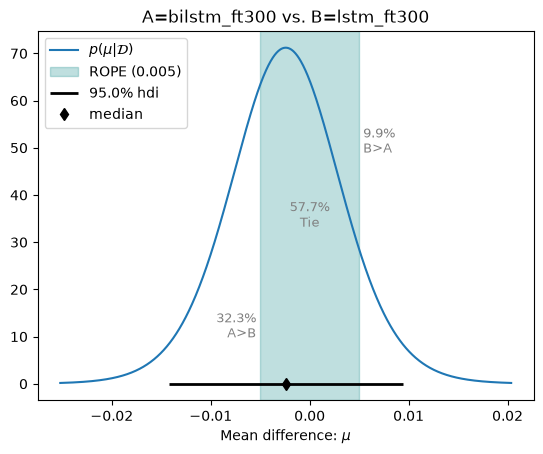

A=gru_ft300 B=lstm_ft300: P(A wins)=0.9819 P(Tie)=0.0180 P(B wins)=0.0002 Effect Size=-3.51


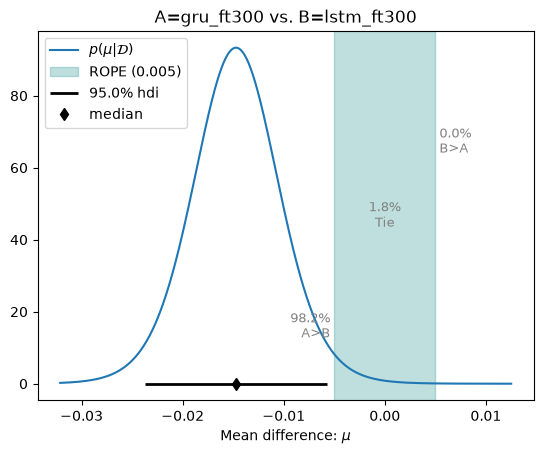

A=lstm_ft300 B=lstm_glove300: P(A wins)=0.4061 P(Tie)=0.5164 P(B wins)=0.0776 Effect Size=-0.63


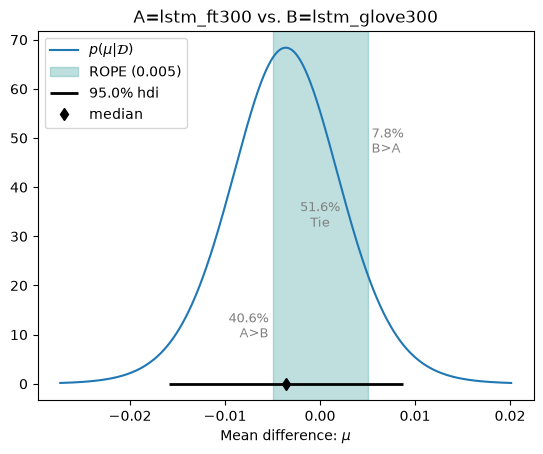

A=pool_ft300 B=lstm_ft300: P(A wins)=0.0000 P(Tie)=0.0000 P(B wins)=1.0000 Effect Size=48.35


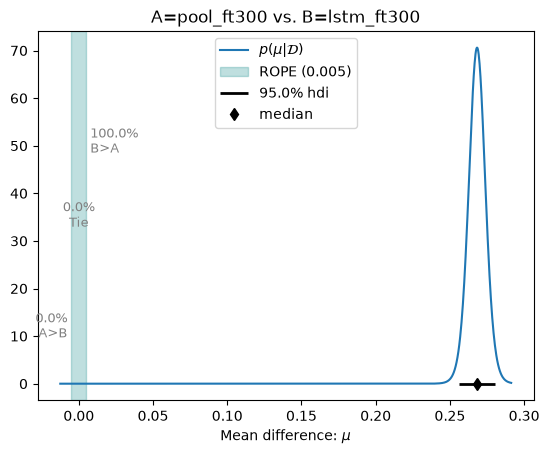

A=lstm_glove50 B=lstm_glove300: P(A wins)=0.0000 P(Tie)=0.0000 P(B wins)=1.0000 Effect Size=7.23


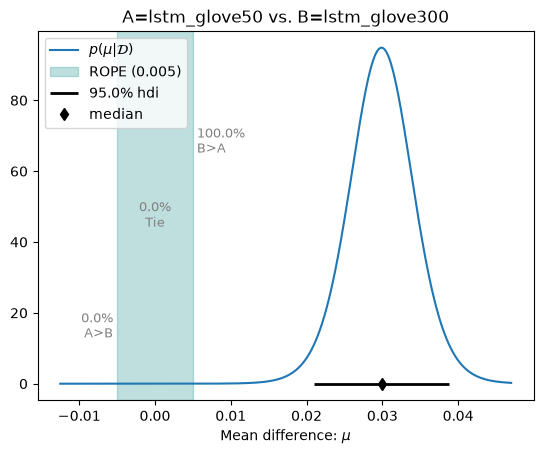

A=lstm_ft300 B=lstm_ft_subword: P(A wins)=1.0000 P(Tie)=0.0000 P(B wins)=0.0000 Effect Size=-6.98


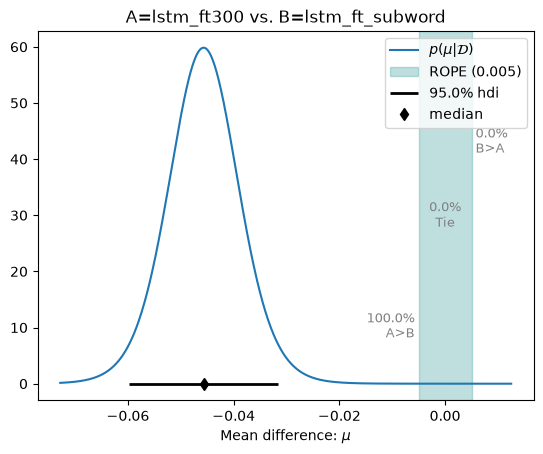

In [9]:
if RUN_ROPE:
    baseline.analysis.plot_comparisons(my_classifiers, config.ROPE_COMPARISONS, config.ROPE_SIZE)
else:
    print("Skipping ROPE plots.")

## Devtest predictions for analysis

Every seed/fold checkpoint of each system is scored on the devtest split of its seed. Needs trained `model.pt` files.

In [10]:
if RUN_DEVTEST_PREDS:
    system_predictions = analysis.collect_devtest_predictions(ANALYSIS_SYSTEMS, devtest_splits)
    for system, checkpoint_predictions in system_predictions.items():
        accuracies = [
            np.mean(predictions == np.array([label for _pair, label in devtest_splits[config.SEEDS.index(seed)]["devtest"]]))
            for (seed, fold), predictions in checkpoint_predictions.items()
        ]
        print(f"{system}: devtest acc {np.mean(accuracies):.4f} ± {np.std(accuracies):.4f} over {len(accuracies)} checkpoints")
    analysis_df = analysis.build_analysis_frame(devtest_splits, system_predictions, tokenizer)
    display(analysis_df)
else:
    analysis_df = None
    print("Skipping devtest predictions (RUN_DEVTEST_PREDS=False) — analysis plots below will skip.")

pool_ft300: devtest acc 0.5207 ± 0.0254 over 15 checkpoints
lstm_ft300: devtest acc 0.7603 ± 0.0315 over 15 checkpoints
bilstm_ft300: devtest acc 0.7873 ± 0.0202 over 15 checkpoints


pair features:   0%|          | 0/200 [00:00<?, ?it/s]

pair features:   0%|          | 0/200 [00:00<?, ?it/s]

pair features:   0%|          | 0/200 [00:00<?, ?it/s]

,system,system_id,item,run,seed,fold,avg_len_words,avg_len_tokens,overlap,label,prediction,correct,avg_len_words_bin,avg_len_tokens_bin,overlap_bin
0,pool_ft300,0,7780,0,0,0,10.5,10.5,0.727273,1,0,0,"(7.999, 16.0]","(7.999, 16.0]","(0.666, 0.826]"
1,pool_ft300,0,1259,0,0,0,12.0,12.0,0.818182,1,0,0,"(7.999, 16.0]","(7.999, 16.0]","(0.666, 0.826]"
2,pool_ft300,0,6745,0,0,0,15.0,15.0,0.857143,0,0,1,"(7.999, 16.0]","(7.999, 16.0]","(0.826, 0.867]"
3,pool_ft300,0,6339,0,0,0,28.0,27.0,0.833333,0,0,1,"(27.6, 39.5]","(23.5, 27.5]","(0.826, 0.867]"
4,pool_ft300,0,3523,0,0,0,22.0,22.0,1.000000,0,0,1,"(19.5, 24.0]","(19.0, 23.5]","(0.944, 1.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8995,bilstm_ft300,2,5220,2,5,4,24.5,24.5,0.850000,1,1,1,"(24.0, 27.6]","(23.5, 27.5]","(0.826, 0.867]"
8996,bilstm_ft300,2,3488,2,5,4,22.5,22.5,0.900000,0,0,1,"(19.5, 24.0]","(19.0, 23.5]","(0.867, 0.9]"
8997,bilstm_ft300,2,5315,2,5,4,23.5,23.5,1.000000,1,1,1,"(19.5, 24.0]","(19.0, 23.5]","(0.944, 1.0]"
8998,bilstm_ft300,2,1585,2,5,4,18.5,18.5,0.947368,1,1,1,"(16.0, 19.5]","(16.0, 19.0]","(0.944, 1.0]"


## Accuracy vs feature bins

Devtest accuracy of every seed/fold checkpoint per bin, for pool vs LSTM vs BiLSTM.

Accuracy vs avg length (words)


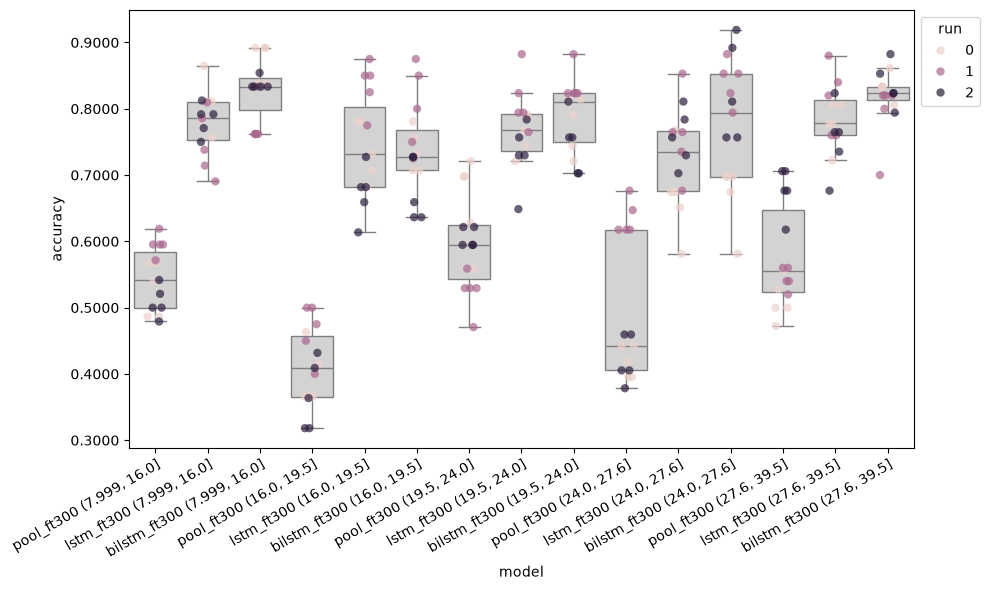

Accuracy vs avg length (tokens)


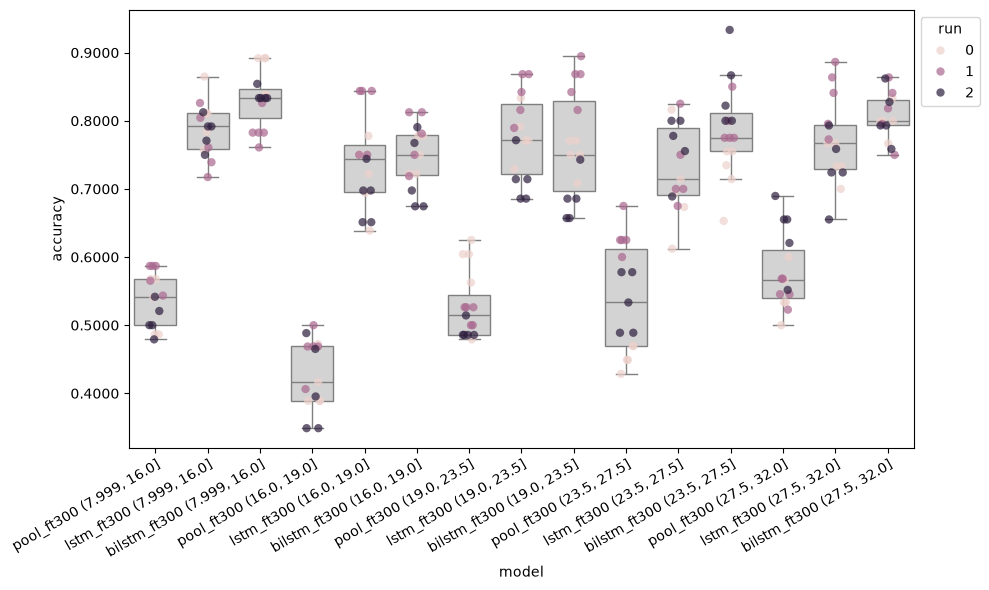

Accuracy vs word overlap


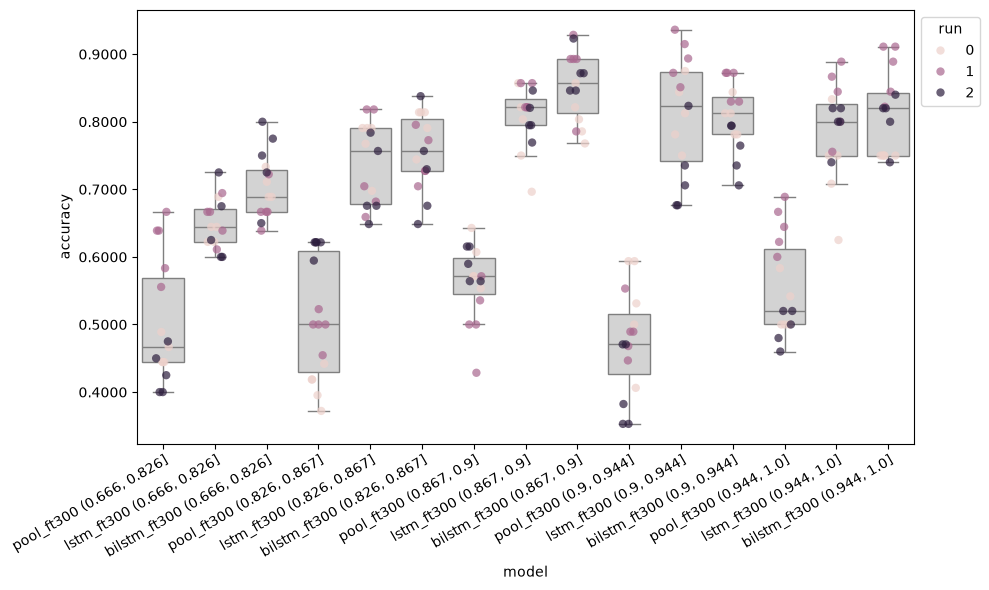

In [11]:
if RUN_BIN_PLOTS and analysis_df is not None:
    for bin_col, title in [
        ("avg_len_words_bin", "Accuracy vs avg length (words)"),
        ("avg_len_tokens_bin", "Accuracy vs avg length (tokens)"),
        ("overlap_bin", "Accuracy vs word overlap"),
    ]:
        print(title)
        baseline.analysis.plot_box_and_points(analysis.bin_accuracy_frame(analysis_df, bin_col), figsize=(10, 6))
else:
    print("Skipping bin plots.")

## PAWS gotcha: high-overlap × non-paraphrase error rate

In [12]:
if RUN_GOTCHA and analysis_df is not None:
    gotcha_df, threshold = analysis.high_overlap_non_paraphrase_error_rate(analysis_df)
    print(f"High-overlap threshold (q={config.OVERLAP_HIGH_QUANTILE}): {threshold:.4f}")
    display(gotcha_df)
else:
    print("Skipping gotcha table.")

High-overlap threshold (q=0.75): 0.9333


,system,threshold,quantile,n,errors,error_rate
0,bilstm_ft300,0.933333,0.75,420,72,0.171429
1,lstm_ft300,0.933333,0.75,420,80,0.190476
2,pool_ft300,0.933333,0.75,420,42,0.100000


## Length × model: uni-LSTM vs BiLSTM

In [13]:
if RUN_LENGTH_X_MODEL and analysis_df is not None:
    length_table = analysis.length_by_model_table(
        analysis_df,
        length_bin_col="avg_len_words_bin",
        systems=("lstm_ft300", "bilstm_ft300"),
    )
    display(length_table)
else:
    print("Skipping length × model table.")

,avg_len_words_bin,acc_lstm_ft300,n_lstm_ft300,acc_bilstm_ft300,n_bilstm_ft300
0,"(7.999, 16.0]",0.777953,635,0.826772,635
1,"(16.0, 19.5]",0.745600,625,0.736000,625
2,"(19.5, 24.0]",0.766667,570,0.784211,570
3,"(24.0, 27.6]",0.724561,570,0.771930,570
4,"(27.6, 39.5]",0.785000,600,0.816667,600


## BDA (correctness ~ system + features)

Uses `part2.analysis.fit_bda_model` via `analysis.fit_bda_from_frame`. Features are the one-hot predicted label
followed by average length (words, tokens) and word overlap; `fit_bda_model` standardises them.

In [14]:
if RUN_BDA and analysis_df is not None:
    mcmc, system_names, feature_names = analysis.fit_bda_from_frame(analysis_df, outcome_space)
    mcmc.print_summary()
else:
    mcmc = None
    print("Skipping BDA.")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
sample: 100%|██████████| 2000/2000 [00:59<00:00, 33.75it/s, 255 steps of size 2.77e-02. acc. prob=0.94]



                   mean       std    median      5.0%     95.0%     n_eff     r_hat
  global_mean      0.83      0.61      0.91     -0.21      1.76   1569.18      1.00
 sys_shift[0]     -0.84      0.61     -0.92     -1.72      0.25   1581.01      1.00
 sys_shift[1]      0.35      0.61      0.27     -0.57      1.39   1566.27      1.00
 sys_shift[2]      0.49      0.61      0.41     -0.42      1.55   1567.74      1.00
       w[0,0]      0.12      0.66      0.12     -0.91      1.20   3102.30      1.00
       w[0,1]     -0.09      0.66     -0.09     -1.11      1.00   3128.08      1.00
       w[0,2]     -0.19      0.17     -0.19     -0.48      0.09   2657.31      1.00
       w[0,3]      0.30      0.18      0.29      0.01      0.59   2656.79      1.00
       w[0,4]      0.06      0.04      0.06      0.00      0.12   5169.70      1.00
       w[1,0]      0.03      0.70      0.01     -1.10      1.16   2529.05      1.00
       w[1,1]      0.03      0.70      0.01     -1.01      1.25   2528.01  

Convergence: r_hat values should be (close to) 1.0 and there should be 0 (or very few) divergences.

In [15]:
if mcmc is not None:
    posterior = mcmc.get_samples()
    print("Weight samples:", posterior["w"].shape)
    print("System shift samples:", posterior["sys_shift"].shape)
    print("Divergences:", int(mcmc.get_extra_fields()["diverging"].sum()))

Weight samples: (4000, 3, 5)
System shift samples: (4000, 3)
Divergences: 0


In [16]:
if mcmc is not None:
    posterior_data = part2.analysis.posterior_to_arviz(
        mcmc,
        system_names=system_names,
        feature_names=feature_names,
    )
else:
    posterior_data = None

In [17]:
az_stats_params = {'point_estimate': 'median', 'ci_kind': 'hdi', 'ci_probs': (0.5, 0.95)}

System shifts (logit scale; higher means more often correct):

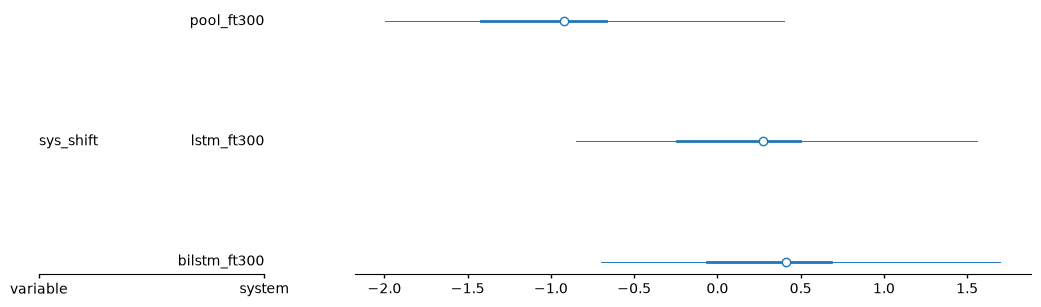

In [18]:
if posterior_data is not None:
    az.plot_forest(
        posterior_data,
        var_names=['sys_shift'],
        combined=True,           # Combine chains
        **az_stats_params
    )

Posterior accuracy:

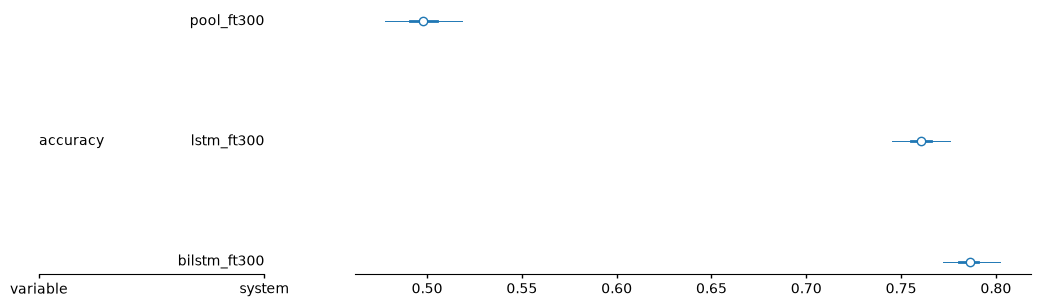

In [19]:
if posterior_data is not None:
    az.plot_forest(
        posterior_data,
        var_names=['accuracy'],
        combined=True,           # Combine chains
        **az_stats_params
    )

Feature weights per system:

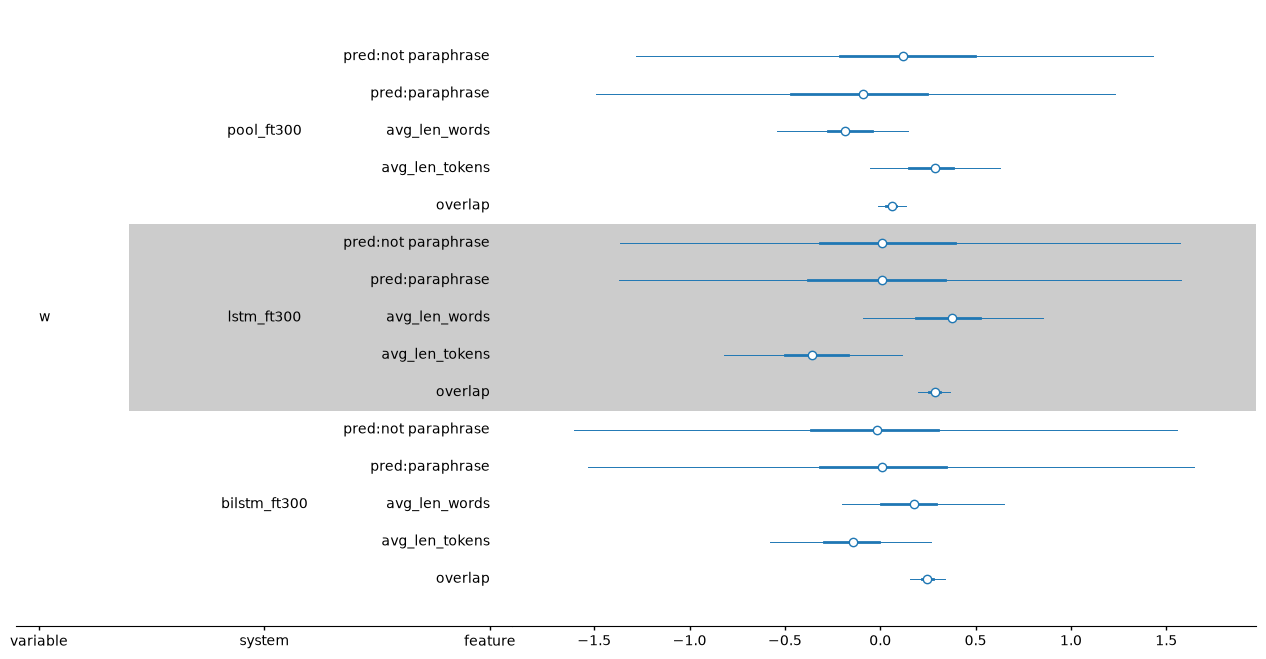

In [20]:
if posterior_data is not None:
    az.plot_forest(
        posterior_data,
        var_names=['w'],
        combined=True,           # Combine chains
        shade_label="system",
        figure_kwargs={
            "figsize": (16, 8),
            "width_ratios": [2, 3],  # Label panel : interval panel
            "layout": "none",
        },
        **az_stats_params,
    )

The same weights grouped by feature, with systems side by side:

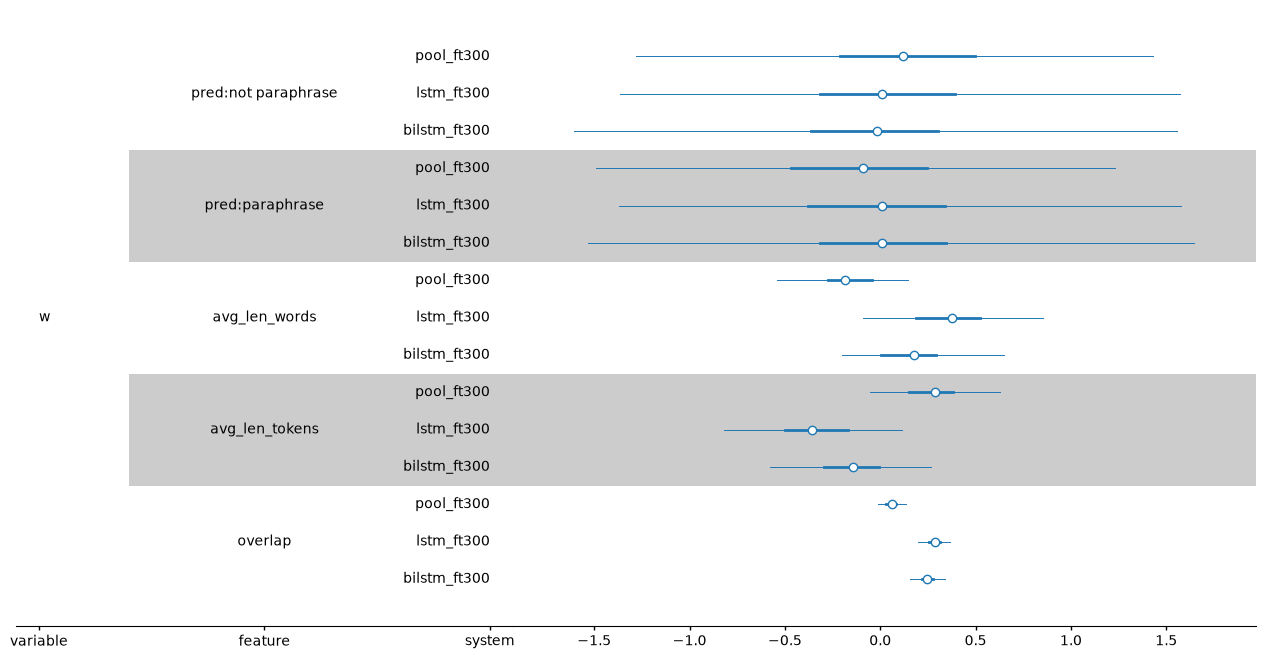

In [21]:
if posterior_data is not None:
    # Plotting copy containing only w, with reordered dimensions.
    plot_data = posterior_data.copy()
    plot_data["posterior"] = (
        posterior_data.posterior["w"]
        .transpose("chain", "draw", "feature", "system")
        .to_dataset()
    )

    az.plot_forest(
        plot_data,
        var_names=["w"],
        combined=True,
        shade_label="feature",
        figure_kwargs={
            "figsize": (16, 8),
            "width_ratios": [2, 3],
            "layout": "none",
        },
        **az_stats_params,
    )

Features are standardised, so weights are comparable: near 0 means the feature does not explain correctness,
positive means the system does better as the feature grows, negative means it struggles.